# Group by Re-ID model

In [ ]:
from pathlib import Path
import json
import pandas as pd

save_csv = True

def parse_folder_name(folder_name: str):
    name_parts = folder_name.split("_")
    if len(name_parts) >= 4:
        detector = name_parts[0]
        tracker = name_parts[1]
        reid_model = "_".join(name_parts[2:-2])
        timestamp = "_".join(name_parts[-2:])
    else:
        detector = folder_name
        tracker = ""
        reid_model = ""
        timestamp = ""
    return detector, tracker, reid_model, timestamp

def flatten(value, prefix="", out=None):
    if out is None:
        out = {}

    if isinstance(value, dict):
        for key, child in value.items():
            next_prefix = f"{prefix}{key}." if prefix else f"{key}."
            flatten(child, next_prefix, out)
    elif isinstance(value, (int, str, float)) and not isinstance(value, bool):
        out[prefix[:-1]] = value

    return out

def process_folder(parent_folder: Path, save_csv: bool = False):
    tracking_rows = []
    reid_rows = []

    for folder in sorted(parent_folder.iterdir()):
        if not folder.is_dir():
            continue

        summary_file = folder / "trackeval_summary.json"
        if not summary_file.exists():
            continue

        detector, tracker, reid_model, timestamp = parse_folder_name(folder.name)

        with summary_file.open("r", encoding="utf-8") as f:
            data = json.load(f)

        tracking_aggregate = data.get("tracking", {}).get("aggregate", {})
        tracking_row = {
            "detector": detector,
            "tracker": tracker,
            "reid_model": reid_model,
            "timestamp": timestamp,
            "folder": folder.name,
            **flatten(tracking_aggregate),
        }
        tracking_rows.append(tracking_row)

        reid_aggregate = data.get("reid", {}).get("global_result", {})
        reid_weights = Path(data.get("reid", {}).get("global_result", {}).get("reid_weights_path", "imagenet")).name if data.get("reid", {}).get("global_result", {}).get("reid_weights_path") else "imagenet"
        fps = data.get("tracking", {}).get("aggregate", {}).get("avg_processing_fps", -1)
        avg_frames = data.get("tracking", {}).get("aggregate", {}).get("avg_processed_frames", -1)
        reid_row = {
            "detector": detector,
            "tracker": tracker,
            "reid_model": reid_model,
            "reid_weights_path": reid_weights,
            "avg_fps": fps,
            "avg_frames": avg_frames,
            "timestamp": timestamp,
            "folder": folder.name,
            **flatten(reid_aggregate),
            "reid_weights_path": reid_weights,
        }
        reid_rows.append(reid_row)

    tracking_df = pd.DataFrame(tracking_rows)
    reid_df = pd.DataFrame(reid_rows)

    if not tracking_df.empty:
        tracking_group_cols = ["detector", "tracker", "reid_model"]
        tracking_numeric_cols = tracking_df.select_dtypes(include="number").columns.tolist()
        tracking_numeric_cols = [c for c in tracking_numeric_cols if c not in tracking_group_cols]

        tracking_grouped_df = (
            tracking_df
            .groupby(tracking_group_cols, as_index=False)
            .agg({**{c: "mean" for c in tracking_numeric_cols}, "folder": "count"})
            .rename(columns={"folder": "run_count"})
        )

        display(tracking_grouped_df)

        if save_csv:
            tracking_output_csv = parent_folder / "tracking_aggregate_average_by_model.csv"
            tracking_grouped_df.to_csv(tracking_output_csv, index=False)
            print(f"Saved tracking grouped averages to {tracking_output_csv}")
    else:
        print("No tracking summaries found.")

    if not reid_df.empty:
        reid_group_cols = ["detector", "tracker", "reid_model", "reid_weights_path"]
        reid_numeric_cols = reid_df.select_dtypes(include="number").columns.tolist()
        reid_numeric_cols = [c for c in reid_numeric_cols if c not in reid_group_cols]

        reid_grouped_df = (
            reid_df
            .groupby(reid_group_cols, as_index=False)
            .agg({**{c: "mean" for c in reid_numeric_cols}, "folder": "count"})
            .rename(columns={"folder": "run_count"})
        )

        display(reid_grouped_df)

        if save_csv:
            reid_output_csv = parent_folder / "reid_aggregate_average_by_model.csv"
            reid_grouped_df.to_csv(reid_output_csv, index=False)
            print(f"Saved ReID grouped averages to {reid_output_csv}")
    else:
        print("No ReID summaries found.")

# folder_list = [ "eval0_reid_imagenet", "eval0_reid_trained_weights", "eval0_reidnight_imagenet", "eval0_reidnight_trained_weights", "eval1_reid_imagenet", "eval1_reid_trained_weights"]
folder_list = ["demo"]
for folder_name in folder_list:
    folder_path = Path(f"./{folder_name}/")
    print(f"\nProcessing folder: {folder_path}")
    process_folder(folder_path, save_csv=save_csv)


Processing folder: eval3


,detector,tracker,reid_model,camera_count,avg_processing_time_sec,avg_processed_frames,avg_processing_fps,clear.CLR_TP,clear.CLR_FN,clear.CLR_FP,...,hota.DetRe,hota.DetPr,hota.AssRe,hota.AssPr,hota.LocA,hota.OWTA,hota.HOTA(0),hota.LocA(0),hota.HOTALocA(0),run_count
0,yolo11n,bytetrack,osnet_ain_x1_0_duke,4.0,98.867012,1925.5500,19.452665,2164.2,4334.8,115.40,...,0.312550,0.661791,0.207376,0.720635,0.752611,0.248535,0.341909,0.674977,0.237765,5
1,yolo11n,bytetrack,osnet_ain_x1_0_imagenet,4.0,97.403423,1814.0000,18.589845,2040.4,4086.0,95.00,...,0.313211,0.665886,0.215875,0.724839,0.753750,0.253911,0.348799,0.677013,0.242870,5
2,yolo11n,bytetrack,osnet_ain_x1_0_market,4.0,96.595953,1806.0500,18.666685,2043.2,4053.8,95.40,...,0.313905,0.662191,0.212242,0.723270,0.751677,0.252232,0.347701,0.673371,0.240874,5
3,yolo11n,bytetrack,osnet_ain_x1_0_ms_d_c,4.0,96.762190,1810.5000,18.682235,2036.8,4094.6,99.40,...,0.313630,0.665769,0.210139,0.720579,0.753772,0.251114,0.345154,0.677693,0.240687,5
4,yolo11n,bytetrack,osnet_ain_x1_0_ms_m_c,4.0,96.867827,1838.9000,18.957055,2084.2,4154.4,95.60,...,0.311898,0.662939,0.216387,0.719109,0.751342,0.253578,0.350122,0.673512,0.242338,5
5,yolo11n,bytetrack,osnet_ain_x1_0_msmt17all,4.0,98.704385,1894.3500,19.162030,2146.0,4237.6,105.60,...,0.312872,0.660061,0.209239,0.718618,0.751102,0.250250,0.346085,0.672596,0.240134,5
6,yolo11n,bytetrack,osnet_ibn_x1_0_duke,4.0,97.515615,1871.0500,19.156520,2128.2,4190.0,102.00,...,0.316422,0.665537,0.207369,0.722265,0.754139,0.250673,0.344487,0.677601,0.240373,5
7,yolo11n,bytetrack,osnet_ibn_x1_0_imagenet,4.0,92.979363,1857.2000,20.107510,2179.8,4208.4,94.80,...,0.317590,0.667660,0.216918,0.722821,0.754263,0.256166,0.350612,0.678204,0.245196,5
8,yolo11n,bytetrack,osnet_ibn_x1_0_market,4.0,97.834574,1871.1500,19.098360,2112.0,4224.8,103.20,...,0.313052,0.662737,0.214101,0.722636,0.752685,0.252621,0.347755,0.674897,0.242008,5
9,yolo11n,bytetrack,osnet_ibn_x1_0_ms_d_c,4.0,97.050507,1867.6500,19.222145,2140.4,4197.4,101.00,...,0.315863,0.666068,0.213920,0.722315,0.753836,0.253855,0.347889,0.676878,0.242537,5


Saved tracking grouped averages to eval3\tracking_aggregate_average_by_model.csv


,detector,tracker,reid_model,reid_weights_path,avg_fps,avg_frames,frame_count,num_gt_ids,num_tracker_ids,num_gt_dets,...,hota.DetRe,hota.DetPr,hota.AssRe,hota.AssPr,hota.LocA,hota.OWTA,hota.HOTA(0),hota.LocA(0),hota.HOTALocA(0),run_count
0,yolo11n,bytetrack,osnet_ain_x1_0,imagenet,18.589845,1814.0000,7256.00,5.0,16.00,1637.4,...,0.497826,0.631515,0.255460,0.502919,0.781151,0.316197,0.402218,0.732502,0.294608,5
1,yolo11n,bytetrack,osnet_ain_x1_0,osnet_ain_ms_d_c.pth.tar,18.682235,1810.5000,7242.00,5.0,11.20,1650.4,...,0.496614,0.632064,0.427530,0.659208,0.780614,0.433873,0.554363,0.731664,0.405611,5
2,yolo11n,bytetrack,osnet_ain_x1_0,osnet_ain_ms_m_c.pth.tar,18.957055,1838.9000,7355.60,5.0,11.40,1670.2,...,0.495391,0.624013,0.421092,0.653330,0.777789,0.428286,0.546917,0.727729,0.398004,5
3,yolo11n,bytetrack,osnet_ain_x1_0,osnet_ain_x1_0_dukemtmcreid_256x128_amsgrad_ep...,19.452665,1925.5500,7702.20,5.0,7.80,1714.8,...,0.497811,0.624757,0.500937,0.641921,0.779133,0.462404,0.592470,0.730184,0.432602,5
4,yolo11n,bytetrack,osnet_ain_x1_0,osnet_ain_x1_0_market1501_256x128_amsgrad_ep10...,18.666685,1806.0500,7224.20,5.0,8.80,1641.4,...,0.498689,0.628912,0.476142,0.646161,0.779452,0.453596,0.581218,0.730825,0.424787,5
5,yolo11n,bytetrack,osnet_ain_x1_0,osnet_ain_x1_0_msmt17_256x128_amsgrad_ep50_lr0...,19.162030,1894.3500,7577.40,5.0,16.40,1697.2,...,0.496953,0.624118,0.378037,0.658667,0.778893,0.406849,0.518562,0.729592,0.378341,5
6,yolo11n,bytetrack,osnet_ibn_x1_0,imagenet,20.107510,1857.2000,7428.80,5.0,15.20,1764.2,...,0.503940,0.634300,0.268978,0.572320,0.779992,0.339300,0.431244,0.731623,0.315514,5
7,yolo11n,bytetrack,osnet_ibn_x1_0,osnet_ibn_ms_d_c.pth.tar,19.222145,1867.6500,7470.60,5.0,9.80,1724.6,...,0.503523,0.632259,0.445610,0.655276,0.780738,0.446051,0.570613,0.732233,0.417782,5
8,yolo11n,bytetrack,osnet_ibn_x1_0,osnet_ibn_ms_m_c.pth.tar,19.370510,1889.5500,7558.20,5.0,11.60,1733.0,...,0.502981,0.631360,0.409775,0.657041,0.780307,0.428329,0.546300,0.732075,0.399970,5
9,yolo11n,bytetrack,osnet_ibn_x1_0,osnet_ibn_x1_0_duke_256x128_amsgrad_ep150_stp6...,19.156520,1871.0500,7484.20,5.0,8.00,1702.4,...,0.502778,0.628467,0.448126,0.627576,0.780308,0.438878,0.562006,0.732155,0.411508,5


Saved ReID grouped averages to eval3\reid_aggregate_average_by_model.csv


In [1]:
from pathlib import Path
import json
import pandas as pd

save_csv = True

def parse_folder_name(folder_name: str):
    name_parts = folder_name.split("_")
    if len(name_parts) >= 4:
        detector = name_parts[0]
        tracker = name_parts[1]
        reid_model = "_".join(name_parts[2:-2])
        timestamp = "_".join(name_parts[-2:])
    else:
        detector = folder_name
        tracker = ""
        reid_model = ""
        timestamp = ""
    return detector, tracker, reid_model, timestamp

def flatten(value, prefix="", out=None):
    if out is None:
        out = {}

    if isinstance(value, dict):
        for key, child in value.items():
            next_prefix = f"{prefix}{key}." if prefix else f"{key}."
            flatten(child, next_prefix, out)
    elif isinstance(value, (int, str, float)) and not isinstance(value, bool):
        out[prefix[:-1]] = value

    return out

def process_folder(parent_folder: Path, save_csv: bool = False):
    tracking_rows = []
    reid_rows = []

    for folder in sorted(parent_folder.iterdir()):
        if not folder.is_dir():
            continue

        summary_file = folder / "trackeval_summary.json"
        if not summary_file.exists():
            continue

        detector, tracker, reid_model, timestamp = parse_folder_name(folder.name)

        with summary_file.open("r", encoding="utf-8") as f:
            data = json.load(f)

        tracking_aggregate = data.get("tracking", {}).get("aggregate", {})
        tracking_row = {
            "detector": detector,
            "tracker": tracker,
            "reid_model": reid_model,
            "timestamp": timestamp,
            "folder": folder.name,
            **flatten(tracking_aggregate),
        }
        tracking_rows.append(tracking_row)

        reid_aggregate = data.get("reid", {}).get("global_result", {})
        reid_weights = Path(data.get("reid", {}).get("global_result", {}).get("reid_weights_path", "imagenet")).name if data.get("reid", {}).get("global_result", {}).get("reid_weights_path") else "imagenet"
        fps = data.get("tracking", {}).get("aggregate", {}).get("avg_processing_fps", -1)
        avg_frames = data.get("tracking", {}).get("aggregate", {}).get("avg_processed_frames", -1)
        reid_row = {
            "detector": detector,
            "tracker": tracker,
            "reid_model": reid_model,
            "reid_weights_path": reid_weights,
            "avg_fps": fps,
            "avg_frames": avg_frames,
            "timestamp": timestamp,
            "folder": folder.name,
            **flatten(reid_aggregate),
            "reid_weights_path": reid_weights,
        }
        reid_rows.append(reid_row)

    tracking_df = pd.DataFrame(tracking_rows)
    reid_df = pd.DataFrame(reid_rows)

    if not tracking_df.empty:
        tracking_group_cols = ["detector", "tracker", "reid_model"]
        tracking_numeric_cols = tracking_df.select_dtypes(include="number").columns.tolist()
        tracking_numeric_cols = [c for c in tracking_numeric_cols if c not in tracking_group_cols]

        tracking_grouped_df = (
            tracking_df
            .groupby(tracking_group_cols, as_index=False)
            .agg({**{c: "mean" for c in tracking_numeric_cols}, "folder": "count"})
            .rename(columns={"folder": "run_count"})
        )

        display(tracking_grouped_df)

        if save_csv:
            tracking_output_csv = parent_folder / "tracking_aggregate_average_by_model.csv"
            tracking_grouped_df.to_csv(tracking_output_csv, index=False)
            print(f"Saved tracking grouped averages to {tracking_output_csv}")
    else:
        print("No tracking summaries found.")

    if not reid_df.empty:
        reid_group_cols = ["detector", "tracker", "reid_model", "reid_weights_path"]
        reid_numeric_cols = reid_df.select_dtypes(include="number").columns.tolist()
        reid_numeric_cols = [c for c in reid_numeric_cols if c not in reid_group_cols]

        reid_grouped_df = (
            reid_df
            .groupby(reid_group_cols, as_index=False)
            .agg({**{c: "mean" for c in reid_numeric_cols}, "folder": "count"})
            .rename(columns={"folder": "run_count"})
        )

        display(reid_grouped_df)

        if save_csv:
            reid_output_csv = parent_folder / "reid_aggregate_average_by_model.csv"
            reid_grouped_df.to_csv(reid_output_csv, index=False)
            print(f"Saved ReID grouped averages to {reid_output_csv}")
    else:
        print("No ReID summaries found.")

# folder_list = [ "eval0_reid_imagenet", "eval0_reid_trained_weights", "eval0_reidnight_imagenet", "eval0_reidnight_trained_weights", "eval1_reid_imagenet", "eval1_reid_trained_weights"]
folder_list = ["demo"]
for folder_name in folder_list:
    folder_path = Path(f"./{folder_name}/")
    print(f"\nProcessing folder: {folder_path}")
    process_folder(folder_path, save_csv=save_csv)


Processing folder: demo


,detector,tracker,reid_model,camera_count,avg_processing_time_sec,avg_processed_frames,avg_processing_fps,clear.CLR_TP,clear.CLR_FN,clear.CLR_FP,...,hota.DetRe,hota.DetPr,hota.AssRe,hota.AssPr,hota.LocA,hota.OWTA,hota.HOTA(0),hota.LocA(0),hota.HOTALocA(0),run_count
0,yolo11n,bytetrack,osnet_x1_0_clonedperson,4.0,79.095963,1650.875,21.111137,2113.5,3839.5,86.0,...,0.325322,0.66769,0.229228,0.72217,0.753712,0.266331,0.366439,0.678064,0.255313,2


Saved tracking grouped averages to demo\tracking_aggregate_average_by_model.csv


,detector,tracker,reid_model,reid_weights_path,avg_fps,avg_frames,frame_count,num_gt_ids,num_tracker_ids,num_gt_dets,...,hota.DetRe,hota.DetPr,hota.AssRe,hota.AssPr,hota.LocA,hota.OWTA,hota.HOTA(0),hota.LocA(0),hota.HOTALocA(0),run_count
0,yolo11n,bytetrack,osnet_x1_0,osnet_clonedperson_ms_d_c.pth,21.111137,1650.875,6603.5,5.0,10.0,1771.0,...,0.512638,0.63097,0.320778,0.516097,0.777559,0.353102,0.452235,0.727567,0.329039,2


Saved ReID grouped averages to demo\reid_aggregate_average_by_model.csv


# Create csv with all runs

In [2]:
from pathlib import Path
import json
import pandas as pd

# folder_list = ["eval0_day", "eval0_daynight", "eval1", "eval2"]
folder_list = ["demo"]
save_csv = True

def parse_folder_name(folder_name: str):
    name_parts = folder_name.split("_")
    if len(name_parts) >= 4:
        detector = name_parts[0]
        tracker = name_parts[1]
        reid_model = "_".join(name_parts[2:-2])
        timestamp = "_".join(name_parts[-2:])
    else:
        detector = folder_name
        tracker = ""
        reid_model = ""
        timestamp = ""
    return detector, tracker, reid_model, timestamp

def flatten(value, prefix="", out=None):
    if out is None:
        out = {}

    if isinstance(value, dict):
        for key, child in value.items():
            next_prefix = f"{prefix}{key}." if prefix else f"{key}."
            flatten(child, next_prefix, out)
    # Added 'str' to the allowed types tuple below
    elif isinstance(value, (int, float, str)) and not isinstance(value, bool):
        out[prefix[:-1]] = value

    return out

def process_folder(parent_folder: Path):
    tracking_rows = []
    reid_rows = []

    for folder in sorted(parent_folder.iterdir()):
        if not folder.is_dir():
            continue

        summary_file = folder / "trackeval_summary.json"
        if not summary_file.exists():
            continue

        detector, tracker, reid_model, timestamp = parse_folder_name(folder.name)

        with summary_file.open("r", encoding="utf-8") as f:
            data = json.load(f)

        tracking_aggregate = data.get("tracking", {}).get("aggregate", {})
        tracking_rows.append(
            {
                "detector": detector,
                "tracker": tracker,
                "reid_model": reid_model,
                "timestamp": timestamp,
                "folder": folder.name,
                **flatten(tracking_aggregate),
            }
        )

        reid_aggregate = data.get("reid", {}).get("global_result", {})
        reid_weights = Path(data.get("reid", {}).get("global_result", {}).get("reid_weights_path", "imagenet")).name if data.get("reid", {}).get("global_result", {}).get("reid_weights_path") else "imagenet"

        fps = data.get("tracking", {}).get("aggregate", {}).get("avg_processing_fps", -1)
        reid_rows.append(
            {
                "detector": detector,
                "tracker": tracker,
                "reid_model": reid_model,
                "reid_weights_path": reid_weights,
                "avg_fps": fps,
                "timestamp": timestamp,
                "folder": folder.name,
                **flatten(reid_aggregate),
                "reid_weights_path": reid_weights,
            }
        )

    tracking_df = pd.DataFrame(tracking_rows)
    reid_df = pd.DataFrame(reid_rows)

    if not tracking_df.empty:
        display(tracking_df.sort_values(["detector", "tracker", "reid_model", "timestamp"]).reset_index(drop=True))
        if save_csv:
            tracking_output_csv = parent_folder / "tracking_aggregate_all_runs.csv"
            tracking_df.to_csv(tracking_output_csv, index=False)
            print(f"Saved {len(tracking_df)} tracking rows to {tracking_output_csv}")
    else:
        print("No tracking summaries found.")

    if not reid_df.empty:
        display(reid_df.sort_values(["detector", "tracker", "reid_model", "timestamp"]).reset_index(drop=True))
        if save_csv:
            reid_output_csv = parent_folder / "reid_aggregate_all_runs.csv"
            reid_df.to_csv(reid_output_csv, index=False)
            print(f"Saved {len(reid_df)} ReID rows to {reid_output_csv}")
    else:
        print("No ReID summaries found.")

for folder_name in folder_list:
    parent_folder = Path(f"./{folder_name}/")
    print(f"Processing folder: {parent_folder}")
    process_folder(parent_folder)

# process_folder(Path("./tracking2_eval1/"))

Processing folder: demo


,detector,tracker,reid_model,timestamp,folder,camera_count,avg_processing_time_sec,avg_processed_frames,avg_processing_fps,clear.CLR_TP,...,hota.AssA,hota.DetRe,hota.DetPr,hota.AssRe,hota.AssPr,hota.LocA,hota.OWTA,hota.HOTA(0),hota.LocA(0),hota.HOTALocA(0)
0,yolo11n,bytetrack,osnet_x1_0_clonedperson,20260726_163427,yolo11n_bytetrack_osnet_x1_0_clonedperson_2026...,4,81.124700,1621.25,20.001625,2087,...,0.207084,0.326618,0.661364,0.214367,0.721939,0.752806,0.258787,0.356129,0.675221,0.248057
1,yolo11n,bytetrack,osnet_x1_0_clonedperson,20260726_164452,yolo11n_bytetrack_osnet_x1_0_clonedperson_2026...,4,77.067226,1680.50,22.220650,2140,...,0.234808,0.324025,0.674017,0.244088,0.722401,0.754618,0.273875,0.376749,0.680907,0.262569


Saved 2 tracking rows to demo\tracking_aggregate_all_runs.csv


,detector,tracker,reid_model,reid_weights_path,avg_fps,timestamp,folder,frame_count,num_gt_ids,num_tracker_ids,...,hota.AssA,hota.DetRe,hota.DetPr,hota.AssRe,hota.AssPr,hota.LocA,hota.OWTA,hota.HOTA(0),hota.LocA(0),hota.HOTALocA(0)
0,yolo11n,bytetrack,osnet_x1_0,osnet_clonedperson_ms_d_c.pth,20.001625,20260726_163427,yolo11n_bytetrack_osnet_x1_0_clonedperson_2026...,6485,5,11,...,0.239886,0.508722,0.629932,0.336379,0.501358,0.778201,0.349329,0.447966,0.725927,0.325191
1,yolo11n,bytetrack,osnet_x1_0,osnet_clonedperson_ms_d_c.pth,22.220650,20260726_164452,yolo11n_bytetrack_osnet_x1_0_clonedperson_2026...,6722,5,9,...,0.246623,0.516555,0.632008,0.305177,0.530836,0.776916,0.356874,0.456504,0.729207,0.332886


Saved 2 ReID rows to demo\reid_aggregate_all_runs.csv


ReID timeline scatter plot

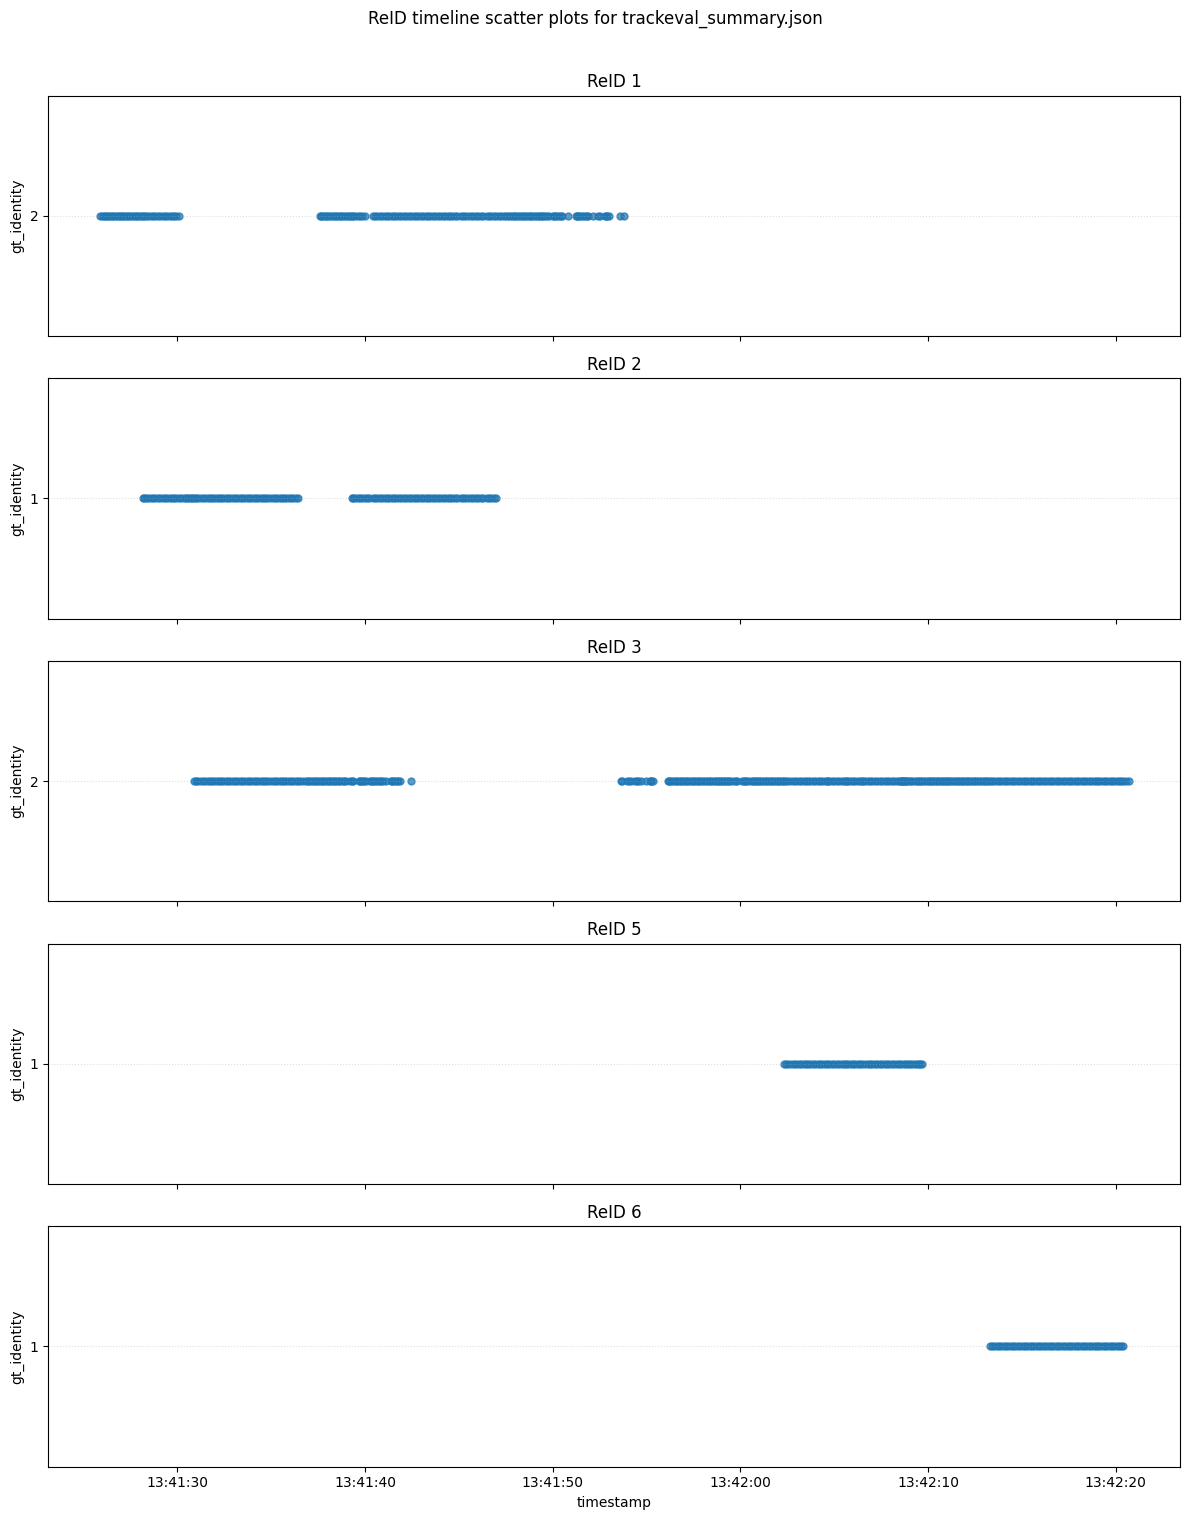

In [ ]:
# Plotting the ReID timeline scatter plots for each ReID id
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

summary_path = Path("./eval0_reidnight_trained_weights/yolo11n_bytetrack_osnet_x1_0_market_20260607_214108/trackeval_summary.json")
if not summary_path.exists():
    candidates = list(Path(".").rglob("trackeval_summary.json"))
    if not candidates:
        raise FileNotFoundError("No trackeval_summary.json found in the workspace")
    summary_path = candidates[0]
    print(f"Using summary file: {summary_path}")

with summary_path.open("r", encoding="utf-8") as f:
    data = json.load(f)

reid_breakdown = data.get("reid", {}).get("global_result", {}).get("global_reid_breakdown", [])
if not reid_breakdown:
    raise ValueError("No 'global_reid_breakdown' data found in the selected summary file")

records = []
for item in reid_breakdown:
    reid_id = str(item.get("reid_id"))
    for point in item.get("timeline", []):
        records.append({
            "reid_id": reid_id,
            "timestamp": pd.to_datetime(point.get("timestamp_utc_ms"), unit="ms"),
            "gt_identity": str(point.get("gt_identity")),
            "camera_id": point.get("camera_id"),
            "frame_id": point.get("frame_id"),
        })

plot_df = pd.DataFrame(records)
if plot_df.empty:
    raise ValueError("No timeline points were found for any ReID id")

plot_df = plot_df.sort_values(["reid_id", "timestamp"])
plot_df["gt_identity_code"] = plot_df["gt_identity"].astype("category").cat.codes

reid_ids = plot_df["reid_id"].unique()
num_plots = len(reid_ids)
fig_height = max(3 * num_plots, 6)
fig, axes = plt.subplots(nrows=num_plots, ncols=1, sharex=True, figsize=(12, fig_height))
if num_plots == 1:
    axes = [axes]

for ax, reid_id in zip(axes, reid_ids):
    group = plot_df[plot_df["reid_id"] == reid_id]
    ax.scatter(group["timestamp"], group["gt_identity_code"], s=25, alpha=0.75)
    yticks = sorted(group["gt_identity_code"].unique())
    yticklabels = [group["gt_identity"].loc[group["gt_identity_code"] == code].iloc[0] for code in yticks]
    ax.set_yticks(yticks)
    ax.set_yticklabels(yticklabels)
    ax.set_ylabel("gt_identity")
    ax.set_title(f"ReID {reid_id}")
    ax.grid(axis="y", linestyle=":", alpha=0.4)

axes[-1].set_xlabel("timestamp")
fig.suptitle(f"ReID timeline scatter plots for {summary_path.name}", y=1.01)
plt.tight_layout()
plt.show()


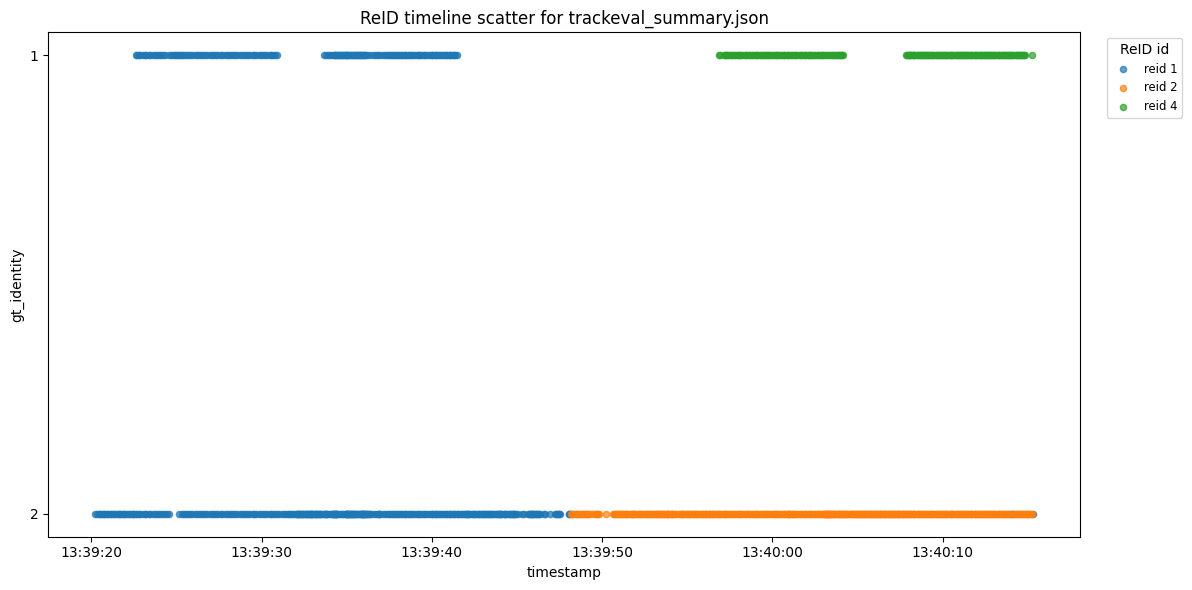

In [ ]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

summary_path = Path("./eval0_reidnight_trained_weights/yolo11n_bytetrack/trackeval_summary.json")
if not summary_path.exists():
    candidates = list(Path(".").rglob("trackeval_summary.json"))
    if not candidates:
        raise FileNotFoundError("No trackeval_summary.json found in the workspace")
    summary_path = candidates[0]
    print(f"Using summary file: {summary_path}")

with summary_path.open("r", encoding="utf-8") as f:
    data = json.load(f)

reid_breakdown = data.get("reid", {}).get("global_result", {}).get("global_reid_breakdown", [])
if not reid_breakdown:
    raise ValueError("No 'global_reid_breakdown' data found in the selected summary file")

records = []
for item in reid_breakdown:
    reid_id = item.get("reid_id")
    for point in item.get("timeline", []):
        records.append({
            "reid_id": str(reid_id),
            "timestamp": pd.to_datetime(point.get("timestamp_utc_ms"), unit="ms"),
            "gt_identity": str(point.get("gt_identity")),
            "camera_id": point.get("camera_id"),
            "frame_id": point.get("frame_id"),
        })

plot_df = pd.DataFrame(records)
if plot_df.empty:
    raise ValueError("No timeline points were found for any ReID id")

fig, ax = plt.subplots(figsize=(12, 6))
for reid_id, group in plot_df.groupby("reid_id"):
    ax.scatter(group["timestamp"], group["gt_identity"], label=f"reid {reid_id}", s=20, alpha=0.7)

ax.set_title(f"ReID timeline scatter for {summary_path.name}")
ax.set_xlabel("timestamp")
ax.set_ylabel("gt_identity")
ax.legend(title="ReID id", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize="small")
plt.tight_layout()
plt.show()


# Generate ReID Timeline scatterplot

In [3]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

# base_folder_path = Path("./eval1_reid_imagenet/")  # Set the parent folder containing subfolders
# folder_list = [ "eval0_reid_imagenet", "eval0_reid_trained_weights", "eval0_reidnight_imagenet", "eval0_reidnight_trained_weights", "eval1_reid_imagenet", "eval1_reid_trained_weights"]
# folder_list = ["eval0_day", "eval0_daynight", "eval1"]
folder_list = ["demo"]

def plot_reid_scatter_for_folder(base_folder_path: Path):
    for subfolder in sorted(base_folder_path.iterdir()):
        if not subfolder.is_dir():
            continue

        summary_file = subfolder / "trackeval_summary.json"
        if not summary_file.exists():
            print(f"Skipping {subfolder.name}: no trackeval_summary.json")
            continue

        with summary_file.open("r", encoding="utf-8") as f:
            data = json.load(f)

        reid_breakdown = data.get("reid", {}).get("global_result", {}).get("global_reid_breakdown", [])
        if not reid_breakdown:
            print(f"Skipping {subfolder.name}: no global_reid_breakdown")
            continue

        records = []
        for item in reid_breakdown:
            reid_id = int(item.get("reid_id"))
            for point in item.get("timeline", []):
                records.append({
                    "reid_id": reid_id,
                    "timestamp": pd.to_datetime(point.get("timestamp_utc_ms"), unit="ms"),
                    "gt_identity": int(point.get("gt_identity")),
                })

        plot_df = pd.DataFrame(records)
        if plot_df.empty:
            print(f"Skipping {subfolder.name}: empty timeline data")
            continue

        plot_df = plot_df.sort_values(["reid_id", "timestamp"])

        # Combined scatter for all reid ids
        fig, ax = plt.subplots(figsize=(14, 6))
        for reid_id, group in plot_df.groupby("reid_id"):
            ax.scatter(group["timestamp"], group["gt_identity"], label=f"reid {reid_id}", s=20, alpha=0.75)

        ax.set_title(f"Combined ReID timeline scatter for {subfolder.name}")
        ax.set_xlabel("timestamp")
        ax.set_ylabel("gt_identity")
        ax.yaxis.get_major_locator().set_params(integer=True)
        ax.legend(title="ReID id", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize="small")
        plt.tight_layout()
        combined_path = summary_file.parent / f"{subfolder.name}_reid_scatter_all.png"
        fig.savefig(combined_path, dpi=150)
        plt.close(fig)

        # Stacked subplots, one row per reid id
        reid_ids = sorted(plot_df["reid_id"].unique())
        num_plots = len(reid_ids)
        fig_height = max(3 * num_plots, 6)
        fig, axes = plt.subplots(nrows=num_plots, ncols=1, sharex=True, figsize=(14, fig_height))
        if num_plots == 1:
            axes = [axes]

        for ax, reid_id in zip(axes, reid_ids):
            group = plot_df[plot_df["reid_id"] == reid_id]
            ax.scatter(group["timestamp"], group["gt_identity"], s=25, alpha=0.75)
            ax.set_ylabel("gt_identity")
            ax.set_title(f"ReID {reid_id}")
            ax.grid(axis="y", linestyle=":", alpha=0.4)
            ax.yaxis.get_major_locator().set_params(integer=True) # Forces integer ticks per subplot

        axes[-1].set_xlabel("timestamp")
        fig.suptitle(f"Stacked ReID subplots for {subfolder.name}")
        plt.tight_layout()
        stacked_path = summary_file.parent / f"{subfolder.name}_reid_scatter_stacked.png"
        fig.savefig(stacked_path, dpi=150)
        plt.close(fig)

        print(f"Saved plots for {subfolder.name}:\n  {combined_path}\n  {stacked_path}")

for folder_name in folder_list:
    base_folder_path = Path(f"./{folder_name}/")
    if not base_folder_path.exists():
        print(f"Folder not found: {base_folder_path}")
        continue
    print(f"Processing folder: {base_folder_path}")
    plot_reid_scatter_for_folder(base_folder_path)

Processing folder: demo
Saved plots for yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427:
  demo\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427_reid_scatter_all.png
  demo\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427_reid_scatter_stacked.png
Saved plots for yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452:
  demo\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452_reid_scatter_all.png
  demo\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452_reid_scatter_stacked.png


# Generate GT Timeline scatter plots

In [4]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

# base_folder_path = Path("./eval0_reidnight_imagenet/")  # Set the parent folder containing subfolders
# folder_list = [ "eval0_reid_imagenet", "eval0_reid_trained_weights", "eval0_reidnight_imagenet", "eval0_reidnight_trained_weights", "eval1_reid_imagenet", "eval1_reid_trained_weights"]
# folder_list = ["eval0_day", "eval0_daynight", "eval1"]
# folder_list = ["eval2"]
folder_list = ["demo"]

def plot_gt_scatter_for_folder(base_folder_path: Path):
    for subfolder in sorted(base_folder_path.iterdir()):
        if not subfolder.is_dir():
            continue

        summary_file = subfolder / "trackeval_summary.json"
        if not summary_file.exists():
            print(f"Skipping {subfolder.name}: no trackeval_summary.json")
            continue

        with summary_file.open("r", encoding="utf-8") as f:
            data = json.load(f)

        gt_breakdown = data.get("reid", {}).get("global_result", {}).get("global_gt_breakdown", [])
        if not gt_breakdown:
            print(f"Skipping {subfolder.name}: no global_gt_breakdown")
            continue

        records = []
        for item in gt_breakdown:
            gt_identity = str(item.get("gt_identity"))
            for point in item.get("timeline", []):
                records.append({
                    "gt_identity": gt_identity,
                    "timestamp": pd.to_datetime(point.get("timestamp_utc_ms"), unit="ms"),
                    "reid_id": str(point.get("reid_id")),
                })

        plot_df = pd.DataFrame(records)
        if plot_df.empty:
            print(f"Skipping {subfolder.name}: empty GT timeline data")
            continue

        plot_df = plot_df.sort_values(["gt_identity", "timestamp"])

        # Combined scatter for all gt ids
        fig, ax = plt.subplots(figsize=(14, 6))
        for gt_identity, group in plot_df.groupby("gt_identity"):
            ax.scatter(group["timestamp"], group["reid_id"], label=f"gt {gt_identity}", s=20, alpha=0.75)

        ax.set_title(f"Combined GT timeline scatter for {subfolder.name}")
        ax.set_xlabel("timestamp")
        ax.set_ylabel("reid_id")
        ax.legend(title="GT id", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize="small")
        plt.tight_layout()
        combined_path = summary_file.parent / f"{subfolder.name}_gt_scatter_all.png"
        fig.savefig(combined_path, dpi=150)
        plt.close(fig)

        # Stacked subplots, one row per gt identity
        gt_ids = plot_df["gt_identity"].unique()
        num_plots = len(gt_ids)
        fig_height = max(3 * num_plots, 6)
        fig, axes = plt.subplots(nrows=num_plots, ncols=1, sharex=True, figsize=(14, fig_height))
        if num_plots == 1:
            axes = [axes]

        for ax, gt_identity in zip(axes, gt_ids):
            group = plot_df[plot_df["gt_identity"] == gt_identity]
            ax.scatter(group["timestamp"], group["reid_id"], s=25, alpha=0.75)
            ax.set_ylabel("reid_id")
            ax.set_title(f"GT {gt_identity}")
            ax.grid(axis="y", linestyle=":", alpha=0.4)

        axes[-1].set_xlabel("timestamp")
        fig.suptitle(f"Stacked GT subplots for {subfolder.name}")
        plt.tight_layout()
        stacked_path = summary_file.parent / f"{subfolder.name}_gt_scatter_stacked.png"
        fig.savefig(stacked_path, dpi=150)
        plt.close(fig)

        print(f"Saved GT plots for {subfolder.name}:\n  {combined_path}\n  {stacked_path}")

for folder_name in folder_list:
    base_folder_path = Path(f"./{folder_name}/")
    if not base_folder_path.exists():
        print(f"Folder not found: {base_folder_path}")
        continue
    print(f"Processing folder: {base_folder_path}")
    plot_gt_scatter_for_folder(base_folder_path)

Processing folder: demo
Saved GT plots for yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427:
  demo\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427_gt_scatter_all.png
  demo\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_163427_gt_scatter_stacked.png
Saved GT plots for yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452:
  demo\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452_gt_scatter_all.png
  demo\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452\yolo11n_bytetrack_osnet_x1_0_clonedperson_20260726_164452_gt_scatter_stacked.png
